### Machine Learning, Assignment 2 (M.Tech AIML, BITS Pilani WILP)
### BITS ID : 2026AJ05329

## 1. Setup

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
# ---- Configuration ----
DATA_PATH = "spambase.data"   
TARGET = "is_spam"            # 1 = spam, 0 = not spam
RANDOM_STATE = 2026
TEST_SIZE = 0.2
MODEL_DIR = "model"

#### 2. Load the data

The UCI file has no header, so the column names (from `spambase.names`) are assigned here: 48 word frequency features, 6 character frequency features, 3 capital letter run length features, then the label.

In [3]:
WORDS = [
    "make", "address", "all", "3d", "our", "over", "remove", "internet",
    "order", "mail", "receive", "will", "people", "report", "addresses",
    "free", "business", "email", "you", "credit", "your", "font", "000",
    "money", "hp", "hpl", "george", "650", "lab", "labs", "telnet", "857",
    "data", "415", "85", "technology", "1999", "parts", "pm", "direct",
    "cs", "meeting", "original", "project", "re", "edu", "table",
    "conference",
]
CHARS = ["semicolon", "paren", "bracket", "exclamation", "dollar", "hash"]
COLUMNS = (
    [f"word_freq_{w}" for w in WORDS]
    + [f"char_freq_{c}" for c in CHARS]
    + ["capital_run_length_average", "capital_run_length_longest",
       "capital_run_length_total"]
    + [TARGET]
)
assert len(COLUMNS) == 58

df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)
print("Raw shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
df.head()

Raw shape: (4601, 58)
Missing values: 0
Duplicate rows: 391


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_paren,char_freq_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


#### 3. Clean and inspect

Duplicate rows are dropped so the same email cannot appear in both the training and test sets. The three `capital_run_length_*` features are on a much larger scale than the rest, which is why the pipelines below include a `StandardScaler`.

Shape after dropping duplicates: (4210, 58)
is_spam
not spam    2531
spam        1679
Name: count, dtype: int64
is_spam
not spam    0.601
spam        0.399
Name: proportion, dtype: float64


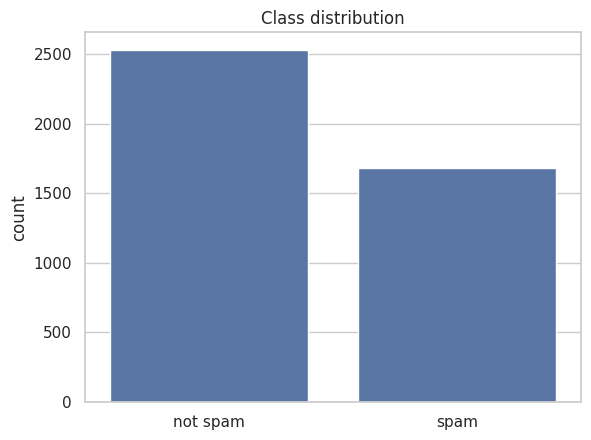

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

labels = df[TARGET].map({0: "not spam", 1: "spam"})
print(labels.value_counts())
print(labels.value_counts(normalize=True).round(3))

ax = sns.countplot(x=labels, order=["not spam", "spam"])
ax.set_title("Class distribution")
ax.set_xlabel("")
plt.show()

In [5]:
df[["capital_run_length_average", "capital_run_length_longest",
    "capital_run_length_total"]].describe().round(2)

,capital_run_length_average,capital_run_length_longest,capital_run_length_total
count,4210.00,4210.00,4210.00
mean,5.38,52.14,291.18
std,33.15,199.58,618.65
min,1.00,1.00,1.00
25%,1.63,7.00,40.00
50%,2.30,15.00,101.50
75%,3.71,44.00,273.75
max,1102.50,9989.00,15841.00


#### 4. Train/test split

Stratified so both sets keep the same spam ratio. The scaler is fitted inside each pipeline on the training data only, which avoids data leakage.

In [6]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Spam share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (3368, 57)  Test: (842, 57)
Spam share  train: 0.399   test: 0.399


#### 5. Models and evaluation

Each model is wrapped in a `Pipeline([StandardScaler, classifier])`, so the saved file takes raw feature values directly. This is what lets the Streamlit app load a model and score an uploaded CSV without any separate preprocessing step.

AUC is computed from predicted probabilities (`predict_proba`); the other metrics use the hard predictions. Precision, Recall and F1 are for the positive class (spam).

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True,
                                  random_state=RANDOM_STATE),
}


def evaluate(pipe, X, y):
    """Return the six metrics plus the hard predictions and spam probabilities."""
    y_pred = pipe.predict(X)
    y_prob = pipe.predict_proba(X)[:, 1]
    scores = {
        "Accuracy": accuracy_score(y, y_pred),
        "AUC": roc_auc_score(y, y_prob),
        "Precision": precision_score(y, y_pred),
        "Recall": recall_score(y, y_pred),
        "F1": f1_score(y, y_pred),
        "MCC": matthews_corrcoef(y, y_pred),
    }
    return scores, y_pred, y_prob

In [8]:
os.makedirs(MODEL_DIR, exist_ok=True)

fitted, preds, probs, rows = {}, {}, {}, []

for name, clf in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    pipe.fit(X_train, y_train)

    scores, y_pred, y_prob = evaluate(pipe, X_test, y_test)
    fitted[name], preds[name], probs[name] = pipe, y_pred, y_prob
    rows.append({"ML Model Name": name, **scores})

    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipe, os.path.join(MODEL_DIR, filename))
    print("trained and saved:", filename)

trained and saved: logistic_regression.joblib
trained and saved: decision_tree.joblib
trained and saved: knn.joblib
trained and saved: naive_bayes.joblib
trained and saved: support_vector_machine.joblib


#### 6. Results

In [9]:
results = pd.DataFrame(rows).round(4)
results.to_csv("results.csv", index=False)
print(results.to_string(index=False))

print("\nBest model per metric:")
print(results.set_index("ML Model Name").idxmax().to_string())

         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.9097 0.9627     0.9088  0.8601 0.8838 0.8109
         Decision Tree    0.9014 0.8970     0.8776  0.8750 0.8763 0.7944
                   KNN    0.8931 0.9457     0.8844  0.8423 0.8628 0.7760
           Naive Bayes    0.8088 0.9376     0.6866  0.9583 0.8000 0.6584
Support Vector Machine    0.9287 0.9712     0.9367  0.8810 0.9080 0.8510

Best model per metric:
Accuracy     Support Vector Machine
AUC          Support Vector Machine
Precision    Support Vector Machine
Recall                  Naive Bayes
F1           Support Vector Machine
MCC          Support Vector Machine


In [10]:
# README-ready markdown table (copy this into README.md and the PDF)
cols = list(results.columns)
lines = ["| " + " | ".join(cols) + " |",
         "|" + "|".join(["---"] * len(cols)) + "|"]
for _, r in results.iterrows():
    lines.append("| " + " | ".join(
        [str(r[cols[0]])] + [f"{r[c]:.4f}" for c in cols[1:]]) + " |")
print("\n".join(lines))

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9097 | 0.9627 | 0.9088 | 0.8601 | 0.8838 | 0.8109 |
| Decision Tree | 0.9014 | 0.8970 | 0.8776 | 0.8750 | 0.8763 | 0.7944 |
| KNN | 0.8931 | 0.9457 | 0.8844 | 0.8423 | 0.8628 | 0.7760 |
| Naive Bayes | 0.8088 | 0.9376 | 0.6866 | 0.9583 | 0.8000 | 0.6584 |
| Support Vector Machine | 0.9287 | 0.9712 | 0.9367 | 0.8810 | 0.9080 | 0.8510 |


#### Confusion matrices (test set)

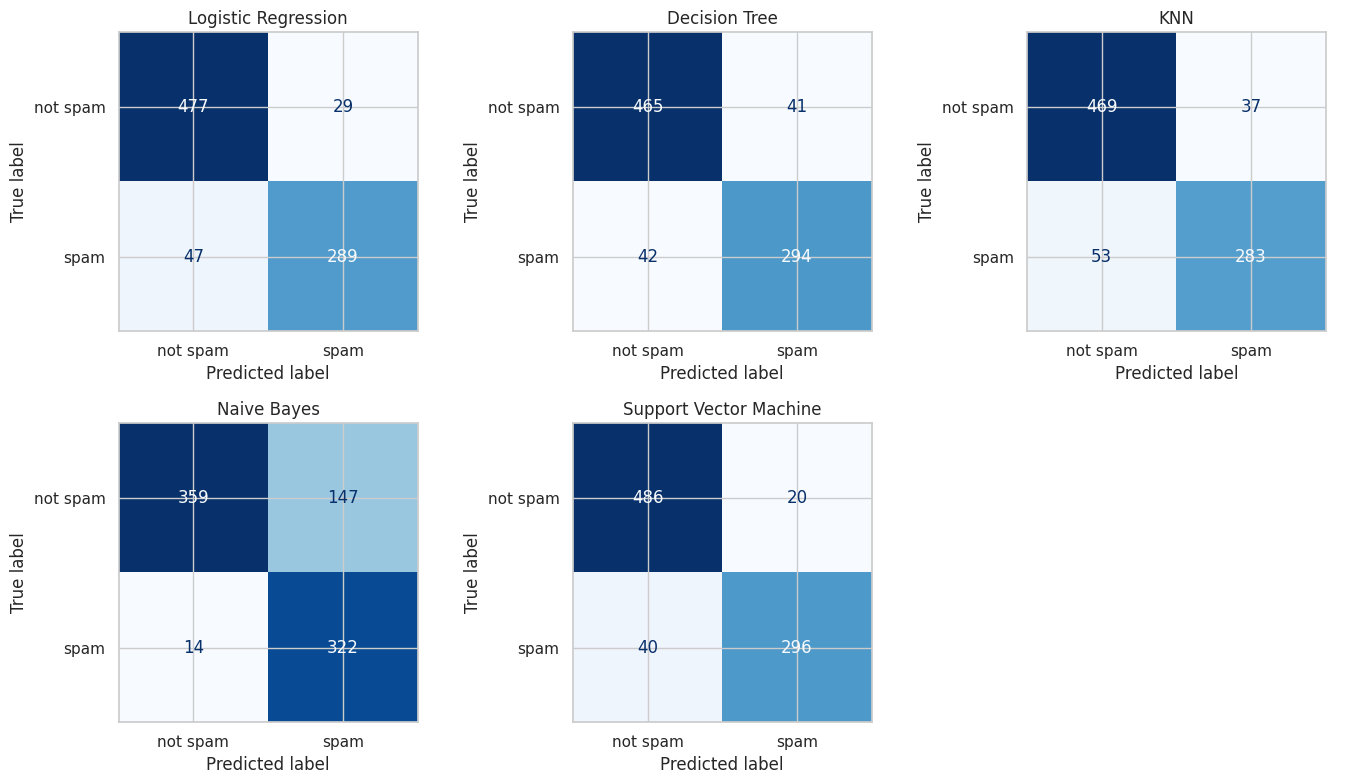

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["not spam", "spam"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
for ax in axes.ravel()[len(models):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

#### ROC curves (test set)

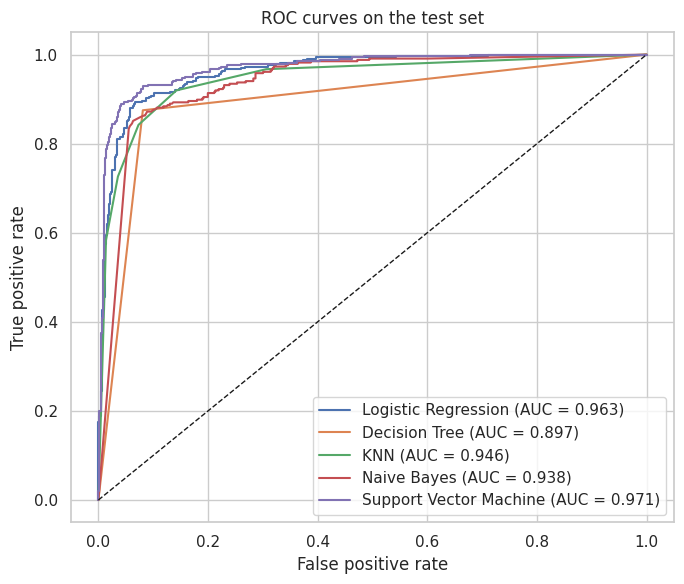

In [12]:
plt.figure(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = results.loc[results["ML Model Name"] == name, "AUC"].iloc[0]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

#### 7. Save the test set for the Streamlit app

Raw (unscaled) features plus the target column. The app uploads this file, loads each saved model, and recomputes the metrics without retraining.

In [13]:
test_df = X_test.copy()
test_df[TARGET] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv:", test_df.shape)

Saved test_data.csv: (842, 58)


#### 8. Sanity check: reload the saved models

Reloads each `.joblib` file and scores `test_data.csv`, the same way the app does. The numbers must match the table above.

In [ ]:
check = pd.read_csv("test_data.csv")
X_chk, y_chk = check.drop(columns=[TARGET]), check[TARGET]

for name in models:
    path = os.path.join(MODEL_DIR, name.lower().replace(" ", "_") + ".joblib")
    reloaded = joblib.load(path)
    scores, _, _ = evaluate(reloaded, X_chk, y_chk)
    expected = results.loc[results["ML Model Name"] == name].iloc[0]
    for metric, value in scores.items():
        assert abs(value - expected[metric]) < 1e-3, (name, metric, value, expected[metric])
print("OK: reloaded models reproduce the results table.")

OK: reloaded models reproduce the results table.


#### 9. Library versions (for `requirements.txt`)

Saved `.joblib` files can fail to load if scikit-learn on Streamlit Cloud differs from the version used here.

In [15]:
from importlib.metadata import version, PackageNotFoundError

for pkg in ["streamlit", "scikit-learn", "numpy", "pandas",
            "matplotlib", "seaborn", "joblib"]:
    try:
        print(f"{pkg}=={version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg}   # not installed here, leave unpinned")

streamlit==1.67.0
scikit-learn==1.9.1
numpy==2.5.4
pandas==2.2.3
matplotlib==3.10.1
seaborn==0.13.2
joblib==1.4.2
